**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values before cleaning:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Missing values after dropna():
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
Cleaned dataset shape: (333, 7)



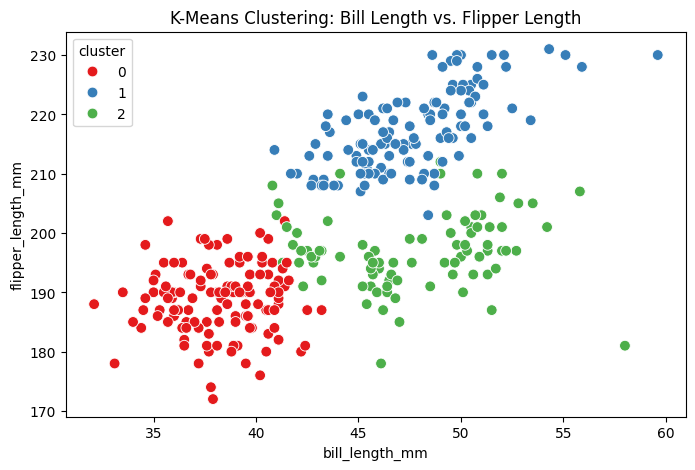

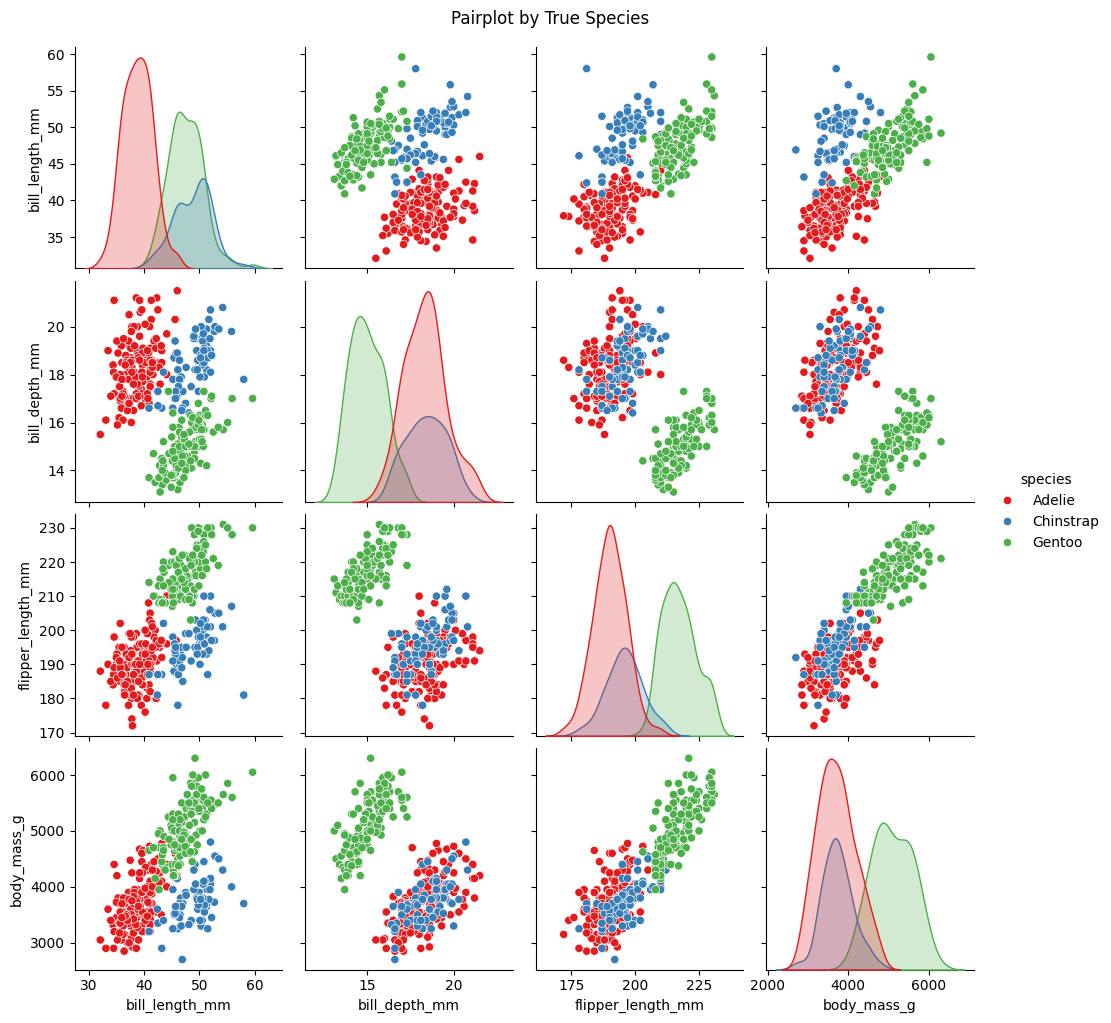

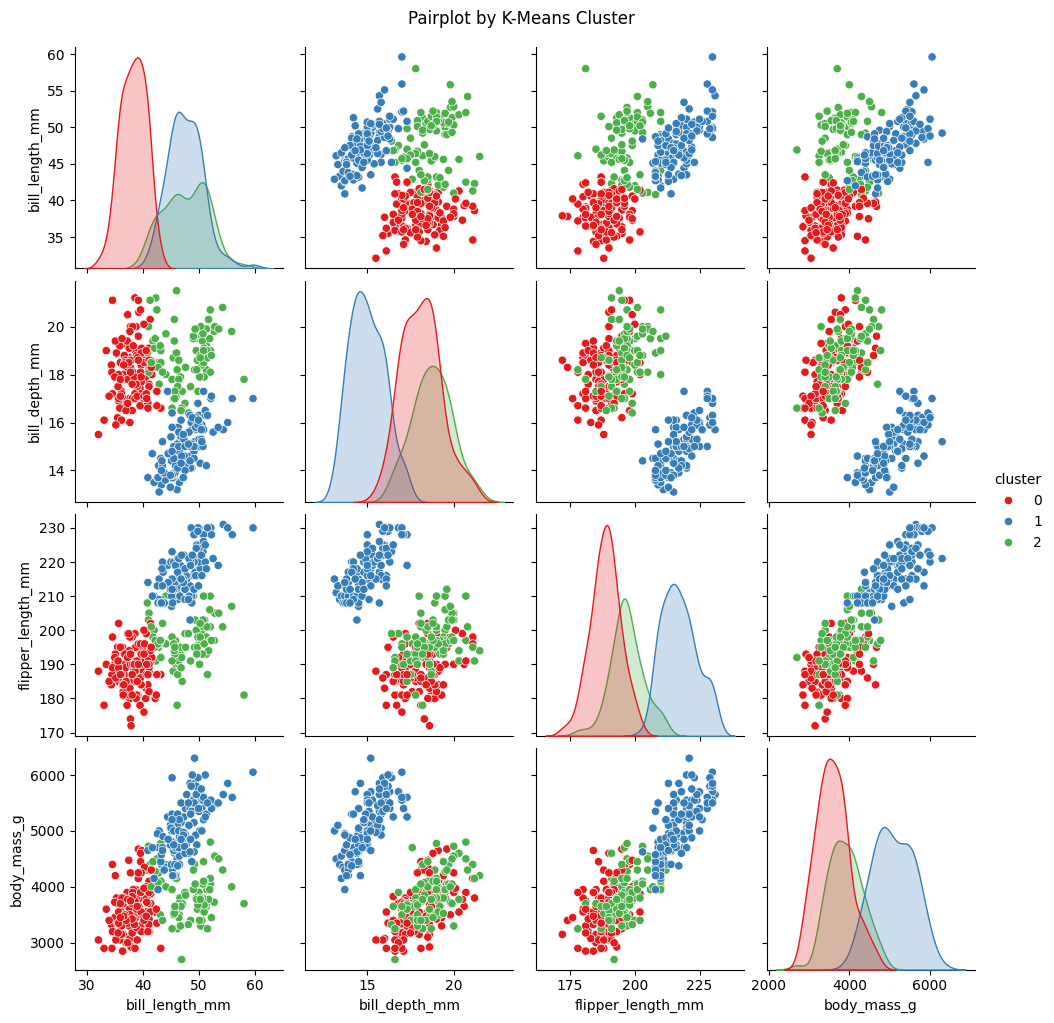

Species Label Mapping: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}

Confusion Matrix (Rows = True Species, Columns = K-Means Cluster):
[[124   0  22]
 [  5   0  63]
 [  0 119   0]]

Adjusted Rand Index (ARI): 0.7994


In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
print("Missing values before cleaning:")
print(penguins.isnull().sum())
penguins_clean = penguins.dropna().copy()
print("\nMissing values after dropna():")
print(penguins_clean.isnull().sum())
print(f"Cleaned dataset shape: {penguins_clean.shape}\n")

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(scaled_data, columns=num_cols, index=penguins_clean.index)

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
penguins_clean['cluster'] = kmeans_labels
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='cluster',
    palette='Set1',
    s=60
)
plt.title('K-Means Clustering: Bill Length vs. Flipper Length')
plt.show()

# Pairplot 1: Real species
sns.pairplot(penguins_clean, vars=num_cols, hue='species', palette='Set1')
plt.suptitle('Pairplot by True Species', y=1.02)
plt.show()

# Pairplot 2: K-Means cluster
sns.pairplot(penguins_clean, vars=num_cols, hue='cluster', palette='Set1')
plt.suptitle('Pairplot by K-Means Cluster', y=1.02)
plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
le = LabelEncoder()
species_numeric = le.fit_transform(penguins_clean['species'])

cm = confusion_matrix(species_numeric, penguins_clean['cluster'])
ari = adjusted_rand_score(penguins_clean['species'], kmeans_labels)

print("Species Label Mapping:", dict(zip(le.classes_, range(len(le.classes_)))))
print("\nConfusion Matrix (Rows = True Species, Columns = K-Means Cluster):")
print(cm)
print(f"\nAdjusted Rand Index (ARI): {ari:.4f}")

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation

#1. Why it is needed to Clean and Scale the Data First?
#Cleaning up missing values:** Out of 344 penguins, 11 were missing some measurement data. Machine learning algorithms like K-Means get confused when they run
#into blank spaces or `NaN`s, so removing those rows ensured that every penguin had complete measurements.
#Scaling/Normalizing:** Because body mass in g is a huge number compared to body depht in mm, an algorithm measuring straight distances would assume body mass is more important than bill depth
#By scaling all measurements to a standardized scale we give every single measurement equal weight.

#2. How Well Did the Algorithm Group the Penguins?
#What K-Means did:Without knowing the names of the species, K-Means was asked to blindly divide the penguins into 3 groups based purely on their physical measurements.
#Looking at the plots:
#Gentoo Penguins:** They stand out clearly. They are the biggest penguins with the longest flippers, so K-Means separated them from the rest easily.
#Adelie vs. Chinstrap Penguins: These two species look a bit more alike in size. While K-Means got most of them right, there is a small amount of overlap
#where a few Adelie and Chinstrap penguins were assigned to each other's groups.

#3. What Do the Evaluation Numbers Mean?
#Confusion Matrix: This table acts like a comparison check between K-Means' guesses and the true biological species:
#It shows that one cluster almost perfectly captures Gentoo penguins, another mostly captures Adelie penguins, and the third captures Chinstrap penguins.
#Adjusted Rand Index (ARI = ~0.78):
#If ARI is an accuracy score on a scale from 0 to 1:
#0.0 means the algorythm just randomly guessed the groupings.
#1.0 means the algorythm matched the real species 100% perfectly.
# So getting 0.78 is a very strong score It proves that physical measurements naturally separate penguin species into distinct groups even when the algorithm isn't told what species it is looking at.


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Contains missing values: False
Manual distance: 5.656854249492381
Numpy distance: 5.656854249492381


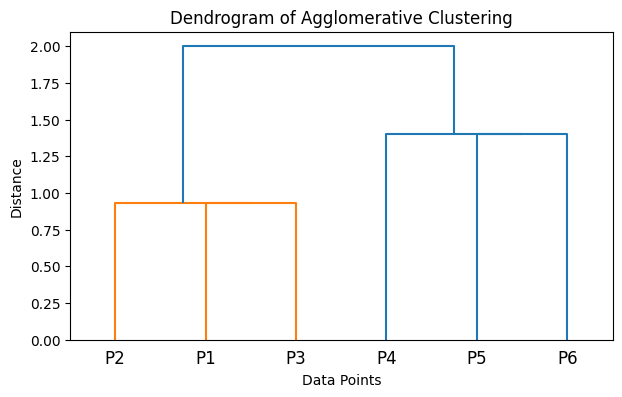

Agglomerative labels: [1 1 1 0 0 0]
K-Means labels:       [0 0 0 1 1 1]


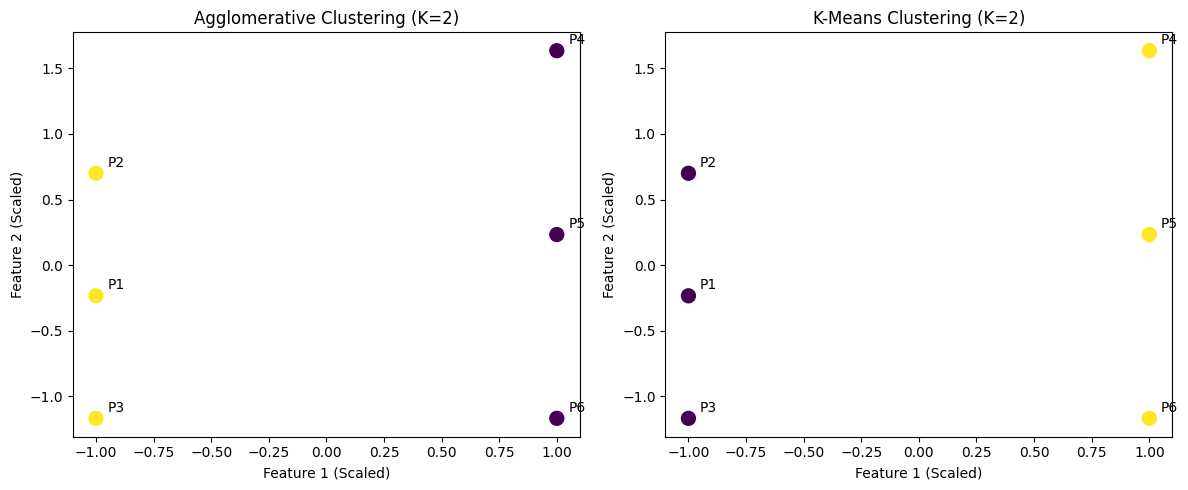

Agglomerative cluster sizes: {np.int64(1): 3, np.int64(0): 3}
K-Means cluster sizes:       {np.int32(0): 3, np.int32(1): 3}


In [10]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import math
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
has_missing = np.isnan(X).any()
print(f"Contains missing values: {has_missing}")

# b) YOUR CODE HERE: normalize X with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    sum_sq = 0.0
    for i in range(len(p1)):
        sum_sq += (p1[i] - p2[i]) ** 2
    return math.sqrt(sum_sq)

# test it
print("Manual distance:", euclidean_distance(X[0], X[3]))
print("Numpy distance:", np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)

Z = linkage(X_scaled, method="single")
plt.figure(figsize=(7, 4))
dendrogram(Z, labels=[f"P{i+1}" for i in range(len(X))])
plt.title("Dendrogram of Agglomerative Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print("Agglomerative labels:", agglo_labels)
print("K-Means labels:      ", kmeans_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Agglomerative Clustering results
axes[0].scatter(
    X_scaled[:, 0], X_scaled[:, 1], c=agglo_labels, cmap="viridis", s=100
)
for i, point in enumerate(X_scaled):
    axes[0].annotate(
        f"P{i+1}", (point[0] + 0.05, point[1] + 0.05), fontsize=10
    )
axes[0].set_title("Agglomerative Clustering (K=2)")
axes[0].set_xlabel("Feature 1 (Scaled)")
axes[0].set_ylabel("Feature 2 (Scaled)")

# Plot K-Means Clustering results
axes[1].scatter(
    X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap="viridis", s=100
)
for i, point in enumerate(X_scaled):
    axes[1].annotate(
        f"P{i+1}", (point[0] + 0.05, point[1] + 0.05), fontsize=10
    )
axes[1].set_title("K-Means Clustering (K=2)")
axes[1].set_xlabel("Feature 1 (Scaled)")
axes[1].set_ylabel("Feature 2 (Scaled)")

plt.tight_layout()
plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1
    return counts


print("Agglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-Means cluster sizes:      ", cluster_sizes(kmeans_labels))

#Interpretation of reuslts

# 1. First, checking for missing values(NaNs) ensures that mathematical distance calculations
# will execure without errors. As in the previous exercice, standarizing the data will prevent
# that fata with naturally larger numeric ranges dominate distance measurement

#2. Comparing manual loop-based distance and Python tool (NumPy's linear algebra function)
#gives the same result. This means that Euclidean disance simply measures straight-line distances
#between coordinates pairs across dimensions.

#3. Agglomerative clustering begins with every data point in its own individual cluster and merges
#the closest pairs step-by-step. The dendrogram visualizes this merging process like a family tree.
#Points P1, P2 and P3 merge at very low distance heights because their horizontal position is at Feature 1 = 1.
#Points P4, P5 and P6 form another distinct group located around Feature 1 = 5. The two large branches only merge
#near the top at a much larger distance height.

#4. Comparison of Agglomerative vs. K-Means Results:
#Both algorithms divide the 6 points into two distinct clusters of equal size (3 points per cluster).
#Points P1, P2, and P3 form Cluster 1 while points P4, P5, and P6 form Cluster 2.
#Although the numeric group IDs assigned by the algorithms may vary the groupings are identical because
#the dataset has a clear two-group structure.




---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values per column before cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64

Missing values after dropna():
carat    0
depth    0
table    0
price    0
dtype: int64
Cleaned dataset shape: (1000, 4)



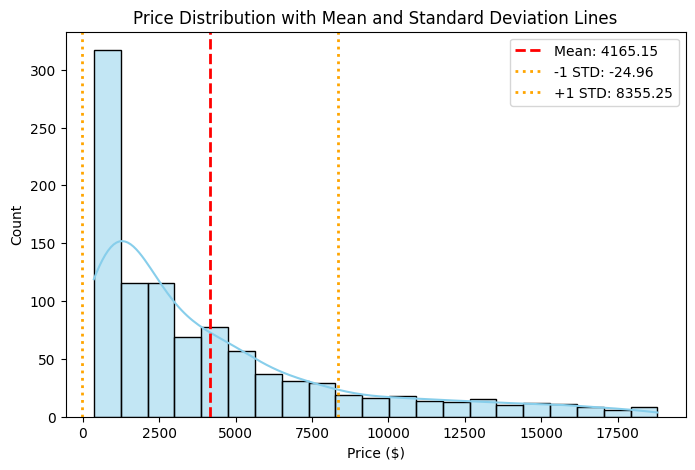

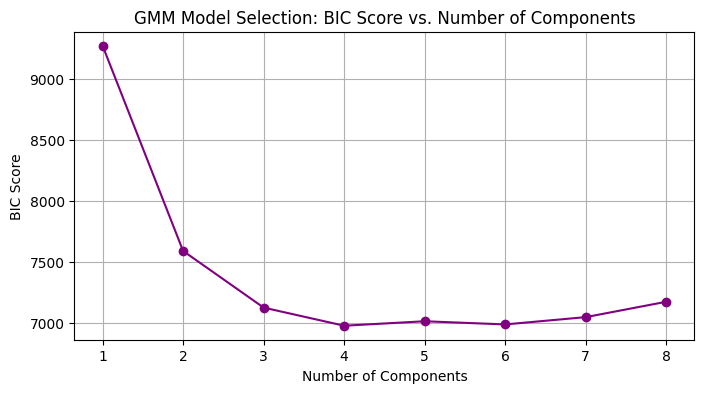

Optimal number of components (lowest BIC): 4


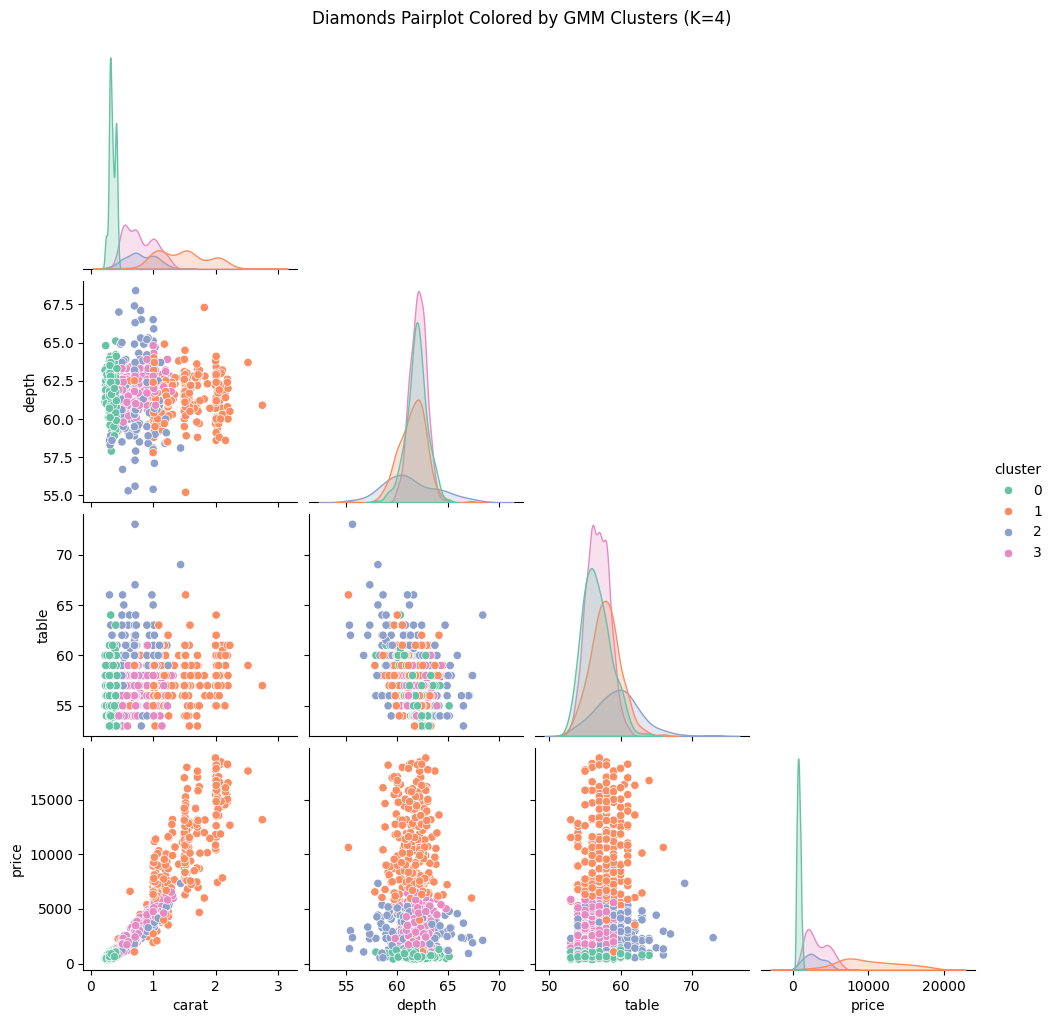

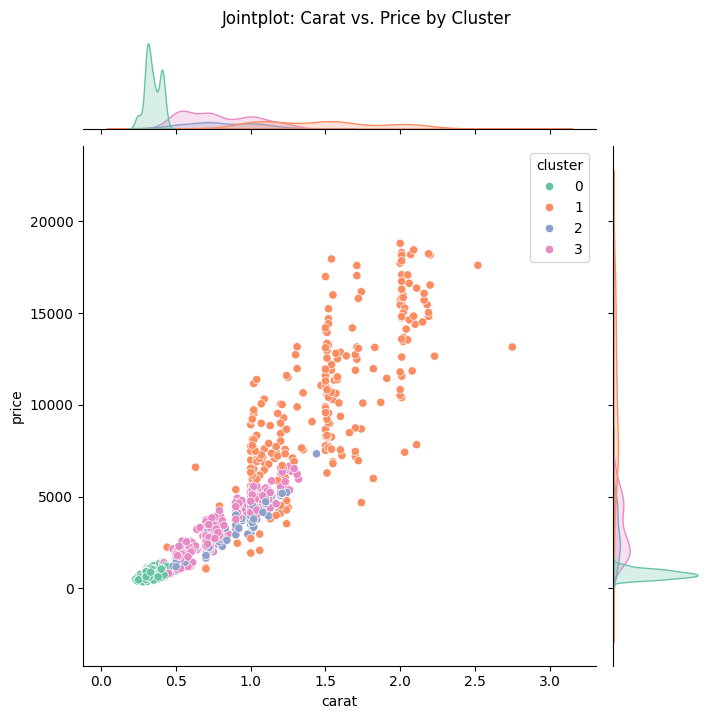

In [18]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
num_cols = ["carat", "depth", "table", "price"]
diamonds_num = diamonds[num_cols].copy()

print("Missing values per column before cleaning:")
print(diamonds_num.isnull().sum())

diamonds_num = diamonds_num.dropna()

print("\nMissing values after dropna():")
print(diamonds_num.isnull().sum())
print(f"Cleaned dataset shape: {diamonds_num.shape}\n")

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
price_mean = diamonds_num["price"].mean()
price_std = diamonds_num["price"].std()

plt.figure(figsize=(8, 5))
sns.histplot(diamonds_num["price"], kde=True, color="skyblue")
plt.axvline(
    price_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {price_mean:.2f}",
)
plt.axvline(
    price_mean - price_std,
    color="orange",
    linestyle=":",
    linewidth=2,
    label=f"-1 STD: {price_mean - price_std:.2f}",
)
plt.axvline(
    price_mean + price_std,
    color="orange",
    linestyle=":",
    linewidth=2,
    label=f"+1 STD: {price_mean + price_std:.2f}",
)
plt.title("Price Distribution with Mean and Standard Deviation Lines")
plt.xlabel("Price ($)")
plt.ylabel("Count")
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))

plt.figure(figsize=(8, 4))
plt.plot(n_components_range, bic, marker="o", linestyle="-", color="purple")
plt.title("GMM Model Selection: BIC Score vs. Number of Components")
plt.xlabel("Number of Components")
plt.ylabel("BIC Score")
plt.xticks(n_components_range)
plt.grid(True)
plt.show()

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = n_components_range[np.argmin(bic)]
print(f"Optimal number of components (lowest BIC): {best_n}")

final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(diamonds_scaled)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num["cluster"] = gmm_labels

# Pairplot across all numeric variables
sns.pairplot(
    diamonds_num,
    vars=num_cols,
    hue="cluster",
    palette="Set2",
    corner=True,
)
plt.suptitle(
    f"Diamonds Pairplot Colored by GMM Clusters (K={best_n})", y=1.02
)
plt.show()

# Jointplot of Carat vs Price
g = sns.jointplot(
    data=diamonds_num,
    x="carat",
    y="price",
    hue="cluster",
    palette="Set2",
    height=7,
)
g.fig.suptitle("Jointplot: Carat vs. Price by Cluster", y=1.02)
plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation

#1. Checking Data Integrity and Price Distribution: there were no missing values in the 1,000 sampled diamonds.The price histogram shows that most
#diamonds are relatively cheap (under $5,000) but a few high-priced outliers stretch the right tail up to nearly $18,000. This makes the standard deviation
#lines wide and asymmetrical relative to the peak.

#2. Model Selection Using BIC Score: BIC tells how well Gaussian Mixture Models fit the dataset without overfitting. When testing 1 group, the score is terrible
#because a single group cannot describe de data. As more components are added, the score gets better and the curve goes down. The lowest point on the graph
#gives the best choie, meaning that it gives enough groups to accurately explain the data without making things too much complicated.

#3. Clustering Patterns in Diamond Features: After setting the best number of components, the algorithm automatically groups the diamonds based
#on how they relate to each other:

# Group 1: Small and lightweighted diamonds that cost the least
# Group 2 and 3: medium-sized diamons with medium prices
# Group 4: Large and heavy diamonds that cost the most
